# Gradientes inestables en una red densa de 20 capas

Una red completamente conectada con 20 capas ocultas de 100 neuronas es propensa a que los gradientes se desvanezcan o exploten durante el entrenamiento. Este notebook compara, en CIFAR-10 y en igualdad de condiciones, tres configuraciones pensadas para mantenerlos estables:

1. Inicialización He con activación ELU.
2. La misma red con Batch Normalization después de cada capa.
3. Red autonormalizada: activación SELU con inicialización LeCun.

Pensado para Colab con GPU.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Flatten, BatchNormalization
from tensorflow.keras.initializers import HeNormal, LecunNormal
from tensorflow.keras.optimizers import Nadam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l1
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

tf.keras.utils.set_random_seed(42)

## 1. Datos

CIFAR-10: 50.000 imágenes de entrenamiento y 10.000 de prueba, de 32×32 píxeles en color y 10 clases. Las últimas 5.000 imágenes de entrenamiento se separan como validación para la parada temprana, de modo que el conjunto de prueba solo se usa al final. Los píxeles se estandarizan con la media y la desviación del entrenamiento, requisito de la red SELU para autonormalizarse.

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

# Validación: últimas 5.000 imágenes de entrenamiento
x_train, x_val = x_train[:-5000], x_train[-5000:]
y_train, y_val = y_train[:-5000], y_train[-5000:]

# Estandarización con estadísticas del entrenamiento
media, desviacion = x_train.mean(), x_train.std()
x_train = (x_train - media) / desviacion
x_val = (x_val - media) / desviacion
x_test = (x_test - media) / desviacion

y_train, y_val, y_test = (to_categorical(y, 10) for y in (y_train, y_val, y_test))

print('Entrenamiento:', x_train.shape, '| Validación:', x_val.shape, '| Prueba:', x_test.shape)

Entrenamiento: (45000, 32, 32, 3) | Validación: (5000, 32, 32, 3) | Prueba: (10000, 32, 32, 3)


## 2. Protocolo común

Las tres redes comparten arquitectura (20 capas ocultas de 100 neuronas, regularización L1 de 0,001), optimizador (Nadam con tasa de aprendizaje de 0,0001), tamaño de lote (128) y parada temprana: hasta 100 épocas, se detiene si la exactitud de validación no mejora en 5 épocas y recupera los pesos de la mejor. Se vigila la exactitud y no la pérdida porque, con 20 capas regularizadas, la penalización L1 domina la pérdida y sigue bajando aunque la red ya no mejore al clasificar.

In [3]:
CAPAS_OCULTAS = 20
NEURONAS = 100

def red_profunda(activacion, inicializador, batch_norm=False):
    modelo = Sequential([Input(shape=(32, 32, 3)), Flatten()])
    for _ in range(CAPAS_OCULTAS):
        modelo.add(Dense(NEURONAS, activation=activacion,
                         kernel_initializer=inicializador(), kernel_regularizer=l1(0.001)))
        if batch_norm:
            modelo.add(BatchNormalization())
    modelo.add(Dense(10, activation='softmax'))
    modelo.compile(optimizer=Nadam(learning_rate=0.0001),
                   loss='categorical_crossentropy', metrics=['accuracy'])
    return modelo

resultados = {}
historias = {}

def entrenar(nombre, modelo):
    parada = EarlyStopping(monitor='val_accuracy', mode='max', patience=5, restore_best_weights=True)
    historia = modelo.fit(x_train, y_train, epochs=100, batch_size=128,
                          validation_data=(x_val, y_val), callbacks=[parada], verbose=0)
    _, exactitud = modelo.evaluate(x_test, y_test, verbose=0)
    mejor = int(np.argmax(historia.history['val_accuracy']))
    resultados[nombre] = {
        'épocas entrenadas': len(historia.history['loss']),
        'mejor época': mejor + 1,
        'exactitud validación': historia.history['val_accuracy'][mejor],
        'exactitud prueba': exactitud,
    }
    historias[nombre] = historia.history
    print(f"{nombre}: {resultados[nombre]['épocas entrenadas']} épocas, "
          f"mejor época {mejor + 1}, exactitud de prueba {exactitud:.3f}")

def curvas(nombre):
    h = historias[nombre]
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
    ejes[0].plot(h['loss'], label='entrenamiento')
    ejes[0].plot(h['val_loss'], label='validación')
    ejes[0].set_title('Pérdida')
    ejes[1].plot(h['accuracy'], label='entrenamiento')
    ejes[1].plot(h['val_accuracy'], label='validación')
    ejes[1].set_title('Exactitud')
    for eje in ejes:
        eje.set_xlabel('Época')
        eje.legend()
        eje.grid(alpha=0.3)
    fig.suptitle(nombre)
    plt.tight_layout()
    plt.show()

## 3. Modelo 1: inicialización He y ELU

La inicialización He escala los pesos según el número de entradas de cada capa, para que la varianza de las activaciones no crezca ni se apague capa tras capa. ELU, a diferencia de ReLU, admite salidas negativas, lo que mantiene la media de las activaciones cerca de cero y evita neuronas muertas.

He + ELU: 21 épocas, mejor época 16, exactitud de prueba 0.484


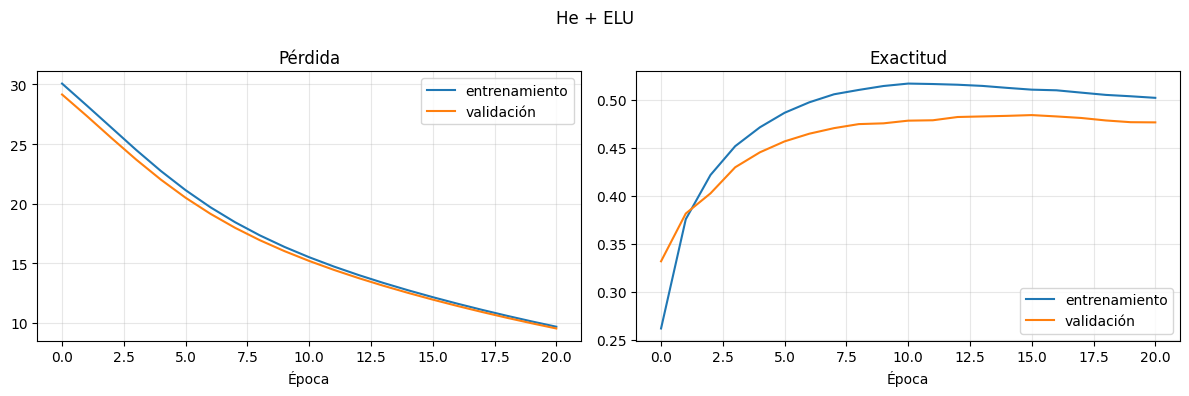

In [4]:
nombre = 'He + ELU'
entrenar(nombre, red_profunda('elu', HeNormal))
curvas(nombre)

## 4. Modelo 2: con Batch Normalization

Después de cada capa densa se normalizan las activaciones con la media y la varianza del lote, lo que estabiliza la distribución que recibe cada capa durante el entrenamiento.

He + ELU + Batch Normalization: 18 épocas, mejor época 13, exactitud de prueba 0.444


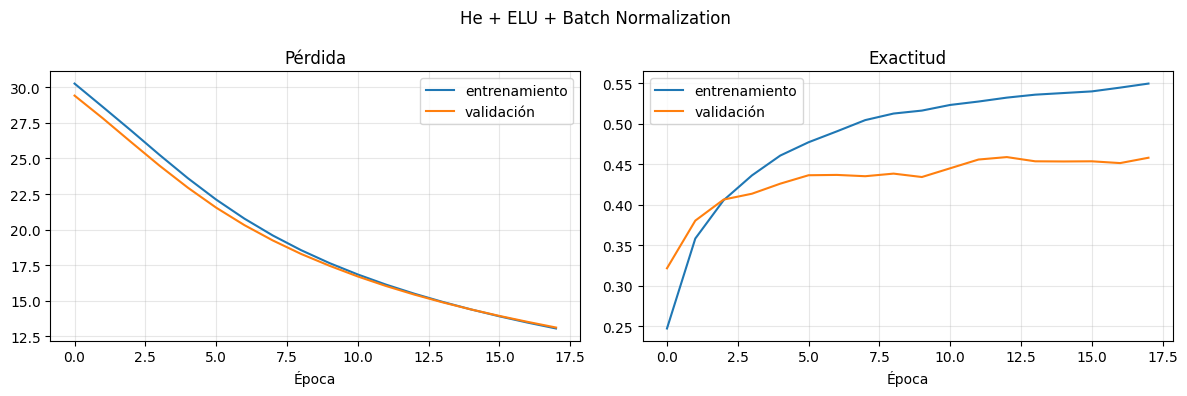

In [5]:
nombre = 'He + ELU + Batch Normalization'
entrenar(nombre, red_profunda('elu', HeNormal, batch_norm=True))
curvas(nombre)

## 5. Modelo 3: red autonormalizada (SELU y LeCun)

Con entradas estandarizadas, activación SELU e inicialización LeCun, cada capa tiende a conservar media 0 y varianza 1 sin capas de normalización explícitas.

SELU + LeCun: 12 épocas, mejor época 7, exactitud de prueba 0.454


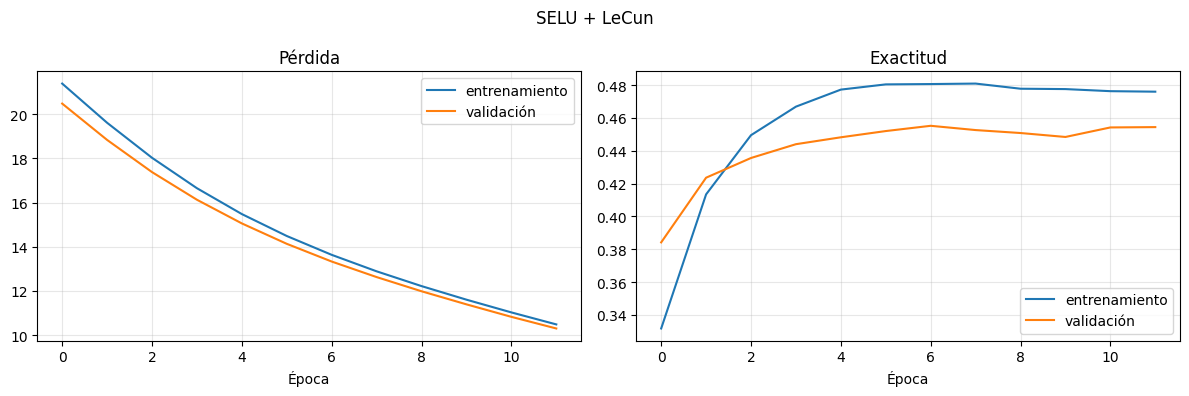

In [6]:
nombre = 'SELU + LeCun'
entrenar(nombre, red_profunda('selu', LecunNormal))
curvas(nombre)

## 6. Comparación

,épocas entrenadas,mejor época,exactitud validación,exactitud prueba
He + ELU,21,16,0.484,0.484
He + ELU + Batch Normalization,18,13,0.459,0.444
SELU + LeCun,12,7,0.455,0.454


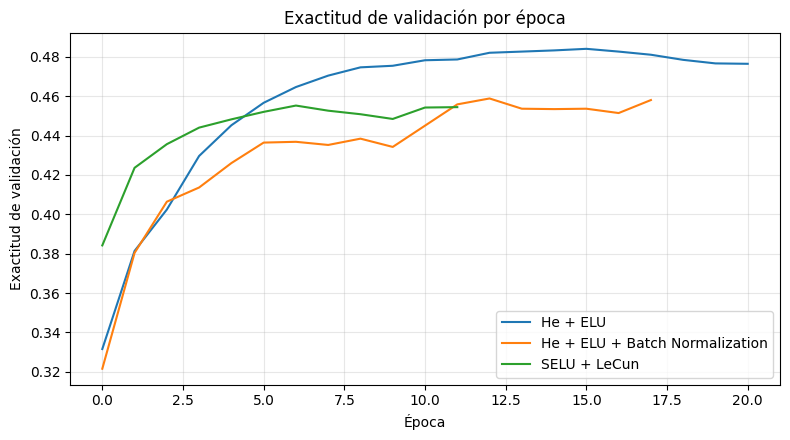

In [7]:
tabla = pd.DataFrame(resultados).T
display(tabla.style.format({'épocas entrenadas': '{:.0f}', 'mejor época': '{:.0f}',
                           'exactitud validación': '{:.3f}', 'exactitud prueba': '{:.3f}'}))

plt.figure(figsize=(8, 4.5))
for nombre, h in historias.items():
    plt.plot(h['val_accuracy'], label=nombre)
plt.xlabel('Época')
plt.ylabel('Exactitud de validación')
plt.title('Exactitud de validación por época')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Análisis**

- Las tres configuraciones entrenan de forma estable una red de 20 capas: la exactitud sube desde la primera época y ninguna diverge ni se queda estancada en el azar (10 %). Es lo que buscan estas técnicas: que el gradiente llegue con un tamaño útil a todas las capas.
- He + ELU obtuvo la mejor exactitud de prueba (0,484, mejor época 16). Desde la época 10, incluso la exactitud de entrenamiento baja un poco: la penalización L1 sigue encogiendo los pesos y limita lo que la red puede ajustar.
- Batch Normalization le da más capacidad de ajuste (la exactitud de entrenamiento sigue subiendo hasta 0,55), pero la de validación se estanca alrededor de 0,46: sobreajusta y termina con 0,444 en prueba.
- La red autonormalizada (SELU + LeCun) es la que converge más rápido (mejor época 7) y llega a 0,454.
- Las tres quedan entre 0,44 y 0,49. Ese es el techo aproximado de una red densa en CIFAR-10: al aplanar la imagen pierde la estructura espacial que aprovecharía una red convolucional. Con una sola semilla, diferencias de 3 a 4 puntos no bastan para declarar una técnica mejor que otra; lo que sí muestran es que las tres hacen entrenable una red profunda.
- La pérdida de las curvas está dominada por la regularización L1 (de unos 30 a 10), no por la clasificación: por eso baja de forma continua aunque la exactitud ya no mejore, y por eso la parada temprana vigila la exactitud.